In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/DSP Project")

DATA_DIR = PROJECT_DIR / "DataSet"
MODELS_DIR = PROJECT_DIR / "Models"
NOTEBOOKS_DIR = PROJECT_DIR / "NoteBooks"
OUTPUT_DIR = PROJECT_DIR / "OutPut"

for folder in [DATA_DIR, MODELS_DIR, NOTEBOOKS_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project path:", PROJECT_DIR)
print("Folders verified successfully!")

Project path: /content/drive/MyDrive/DSP Project
Folders verified successfully!


In [4]:
import pandas as pd

DATA_PATH = DATA_DIR / "creditcard.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nClass distribution:")
print(df["Class"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

Dataset shape: (284807, 31)

First five rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Missing values: 0


In [7]:
# Cell 1: Import required libraries, define project paths,
# load the credit card transaction dataset, and inspect its structure.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Define project directories
PROJECT_DIR = Path("/content/drive/MyDrive/DSP Project")
DATA_DIR = PROJECT_DIR / "DataSet"
OUTPUT_DIR = PROJECT_DIR / "OutPut"
MODELS_DIR = PROJECT_DIR / "Models"

# Load dataset
DATA_PATH = DATA_DIR / "creditcard.csv"
df = pd.read_csv(DATA_PATH)

# Display basic dataset information
print("Dataset Shape:", df.shape)
print("Total Transactions:", len(df))
print("Total Features:", df.shape[1] - 1)

# Display first five records
display(df.head())

# Inspect data types and missing values
print("\nDataset Information:")
df.info()

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

# Display target class distribution
print("\nClass Distribution:")
print(df["Class"].value_counts().sort_index())

print("\nFraud Percentage:", round(df["Class"].mean() * 100, 4), "%")

Dataset Shape: (284807, 31)
Total Transactions: 284807
Total Features: 30


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f

,Transaction_Type,Count,Percentage
0,Legitimate,284315,99.8273
1,Fraudulent,492,0.1727


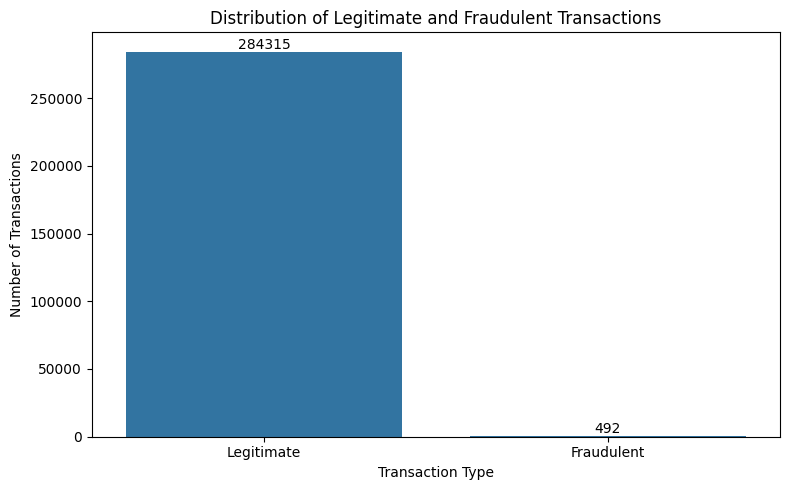

In [8]:
# Cell 3: Calculate the count and percentage of legitimate and
# fraudulent transactions and visualize the class imbalance.

class_counts = df["Class"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "Transaction_Type": ["Legitimate", "Fraudulent"],
    "Count": [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ]
})

class_summary["Percentage"] = (
    class_summary["Count"] / len(df) * 100
).round(4)

display(class_summary)

# Visualize transaction distribution
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=class_summary,
    x="Transaction_Type",
    y="Count"
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

Transaction Amount Statistics:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


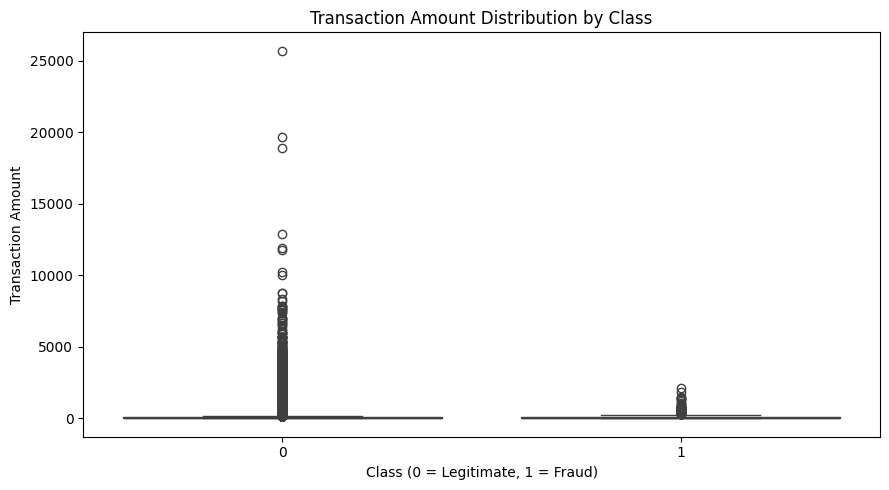

In [9]:
# Cell 4: Compare transaction amount distributions for legitimate
# and fraudulent transactions using descriptive statistics and boxplots.

print("Transaction Amount Statistics:")
display(
    df.groupby("Class")["Amount"]
    .describe()
    .round(2)
)

# Compare amount distributions
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

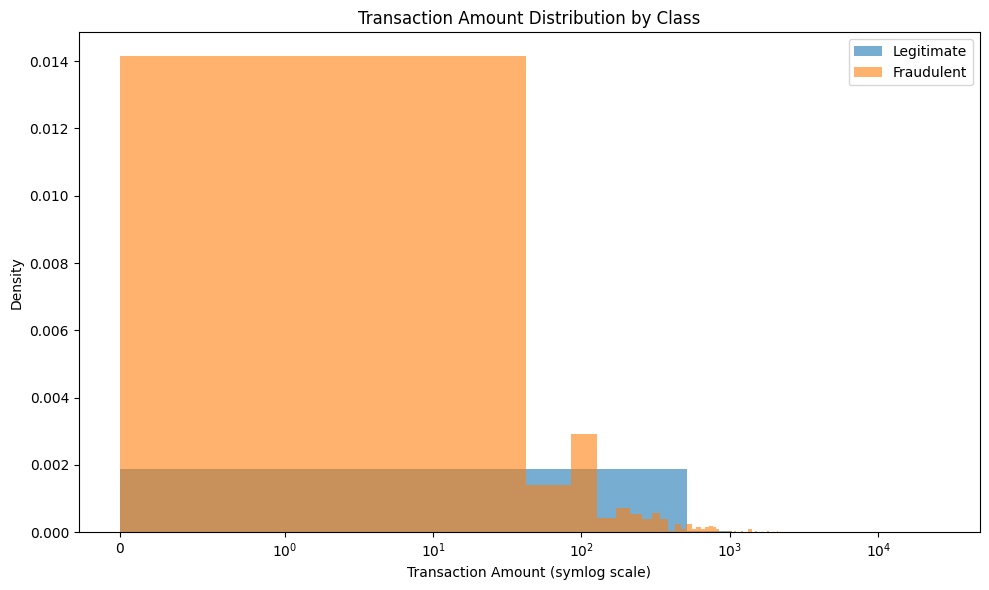

In [10]:
# Cell 5: Compare legitimate and fraudulent transaction amounts
# using histograms to examine their distributions and overlap.

plt.figure(figsize=(10, 6))

for class_value, label in [(0, "Legitimate"), (1, "Fraudulent")]:
    amounts = df.loc[df["Class"] == class_value, "Amount"]

    plt.hist(
        amounts,
        bins=50,
        alpha=0.6,
        density=True,
        label=label
    )

plt.xscale("symlog", linthresh=1)
plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount (symlog scale)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Cell 6: Check data quality by identifying missing values,
# duplicate records, and duplicate records within each class.

print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nTotal missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

print("\nDuplicate counts by class:")
display(
    df.loc[df.duplicated(keep=False), "Class"]
    .value_counts()
    .rename_axis("Class")
    .to_frame("Rows in Duplicate Groups")
)

Missing values per column:


,Missing Values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0



Total missing values: 0
Total duplicate rows: 1081

Duplicate counts by class:


,Rows in Duplicate Groups
Class,
0,1822
1,32


In [12]:
# Cell 7: Investigate duplicate transactions by examining repeated
# records, their class labels, and the number of occurrences.

duplicate_mask = df.duplicated(keep=False)
duplicate_df = df.loc[duplicate_mask].copy()

print("Rows belonging to duplicate groups:", len(duplicate_df))

print("\nClass distribution among duplicate-group rows:")
display(duplicate_df["Class"].value_counts().sort_index())

print("\nMost frequently repeated complete records:")
display(
    df.groupby(list(df.columns), dropna=False)
      .size()
      .reset_index(name="Occurrences")
      .query("Occurrences > 1")
      .sort_values("Occurrences", ascending=False)
      .head(10)
)

Rows belonging to duplicate groups: 1854

Class distribution among duplicate-group rows:


,count
Class,
0,1822
1,32



Most frequently repeated complete records:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Occurrences
267315,163152.0,-1.196037,1.585949,2.883976,3.378471,1.511706,3.717077,0.585362,-0.156001,0.122648,...,0.524395,-0.355170,-0.869790,-0.133198,0.327804,-0.035702,-0.858197,7.56,0,18
267314,163152.0,-1.203617,1.574009,2.889277,3.381404,1.538663,3.698747,0.560211,-0.150911,0.124136,...,0.522223,-0.357329,-0.870174,-0.134166,0.327019,-0.042648,-0.855262,1.51,0,18
281138,170731.0,2.033492,0.766969,-2.107555,3.631952,1.348594,-0.499907,0.945159,-0.286392,-1.370581,...,0.658545,-0.102644,0.580535,0.643637,0.347240,-0.116618,-0.078601,0.76,0,9
47058,43153.0,-2.086016,2.203265,1.654339,2.941050,-1.683045,0.529728,-1.352162,1.793449,-0.723686,...,0.567241,-0.035345,0.370201,0.157378,0.440341,0.210230,0.090558,0.76,0,9
102059,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,...,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.00,1,6
103350,68780.0,0.488552,-0.922367,1.673494,3.003203,-1.465758,0.749788,-0.700551,0.383919,0.511891,...,0.606800,-0.222559,0.405858,0.080003,0.148637,0.022034,0.087126,282.98,0,5
94247,64947.0,-6.370459,3.306401,1.724991,-1.589581,0.174936,0.232403,2.967884,-3.421005,7.937413,...,0.387513,-0.364322,0.480224,0.154904,-0.535302,-4.787907,-3.696616,12.33,0,5
94246,64947.0,-6.373391,3.301783,1.727041,-1.588447,0.185362,0.225313,2.958156,-3.419036,7.937988,...,0.386673,-0.365157,0.480075,0.154530,-0.535606,-4.790593,-3.695480,9.99,0,5
94248,64947.0,-6.342969,3.349697,1.705767,-1.600219,0.077178,0.298877,3.059092,-3.439462,7.932015,...,0.395387,-0.356491,0.481618,0.158414,-0.532454,-4.762716,-3.707261,34.27,0,5
94245,64947.0,-6.378440,3.293830,1.730572,-1.586493,0.203319,0.213103,2.941403,-3.415646,7.938980,...,0.385227,-0.366595,0.479819,0.153885,-0.536129,-4.795220,-3.693525,5.96,0,5


Top 10 features correlated with the fraud label:


,Correlation with Class
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V11,0.154876
V4,0.133447
V18,-0.111485


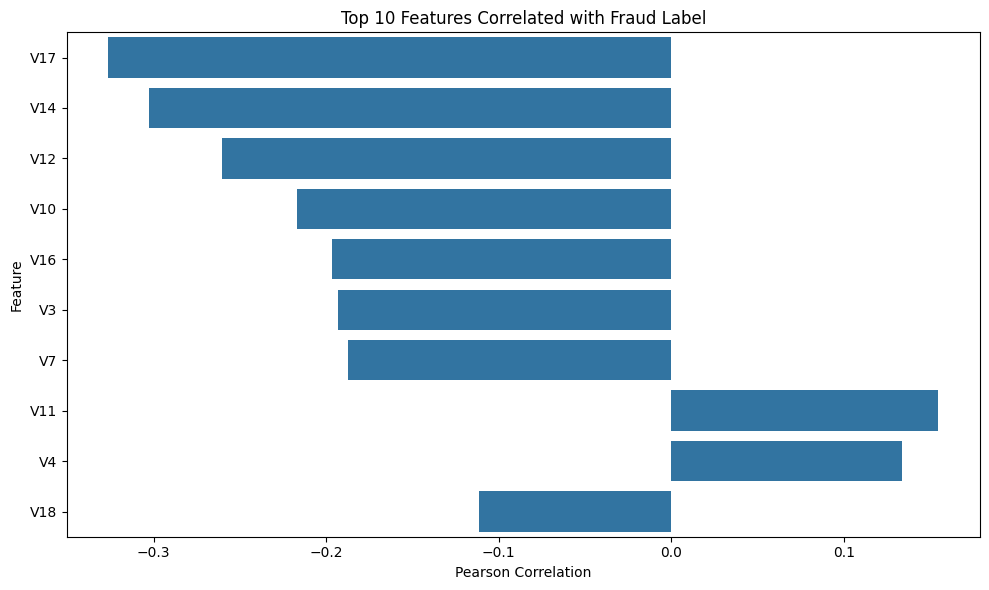

In [13]:
# Cell 8: Calculate correlations between input features and the fraud
# label, then visualize the 10 features with the strongest correlations.

correlations = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)

print("Top 10 features correlated with the fraud label:")
display(correlations.head(10).to_frame("Correlation with Class"))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=correlations.head(10).values,
    y=correlations.head(10).index
)

plt.title("Top 10 Features Correlated with Fraud Label")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [14]:
# Cell 9: Separate input features and target labels, split the dataset
# into stratified training and testing sets, and standardize the features.

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df.drop(columns=["Class"])
y = df["Class"]

# Split dataset while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Standardize features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display dataset split information
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

print("\nTraining fraud percentage:", round(y_train.mean() * 100, 4), "%")
print("Testing fraud percentage:", round(y_test.mean() * 100, 4), "%")

Training samples: 227845
Testing samples: 56962

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64

Training fraud percentage: 0.1729 %
Testing fraud percentage: 0.172 %


In [15]:
# Cell 10: Train a Logistic Regression baseline with balanced class
# weights to account for the small number of fraudulent transactions.

from sklearn.linear_model import LogisticRegression

# Initialize and train the model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed successfully.")

Logistic Regression training completed successfully.


Classification Report:
              precision    recall  f1-score   support

           0     0.9999    0.9756    0.9876     56864
           1     0.0610    0.9184    0.1144        98

    accuracy                         0.9755     56962
   macro avg     0.5304    0.9470    0.5510     56962
weighted avg     0.9982    0.9755    0.9861     56962

PR-AUC (Average Precision): 0.719
ROC-AUC: 0.9721


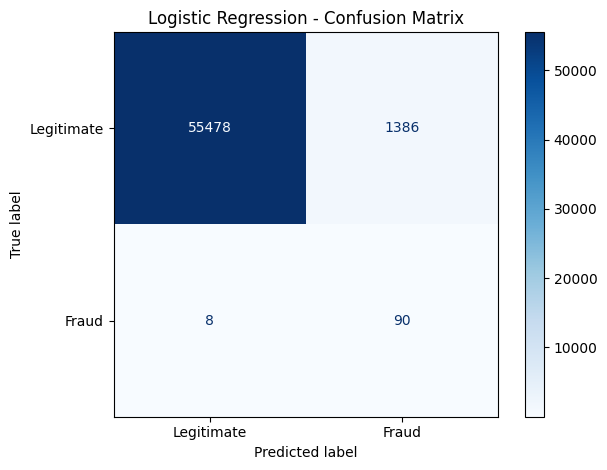

In [16]:
# Cell 11: Evaluate Logistic Regression using precision, recall,
# F1-score, PR-AUC, ROC-AUC, and the confusion matrix.

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Generate predictions and fraud probabilities
y_pred = lr_model.predict(X_test_scaled)
y_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

# Display classification metrics
print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4, zero_division=0))

print("PR-AUC (Average Precision):", round(average_precision_score(y_test, y_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [17]:
# Cell 12: Train a balanced Random Forest classifier as the second
# baseline model for detecting fraudulent credit card transactions.

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully.")

Random Forest training completed successfully.


Random Forest Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56864
           1     0.9610    0.7551    0.8457        98

    accuracy                         0.9995     56962
   macro avg     0.9803    0.8775    0.9227     56962
weighted avg     0.9995    0.9995    0.9995     56962

PR-AUC: 0.8589
ROC-AUC: 0.9572


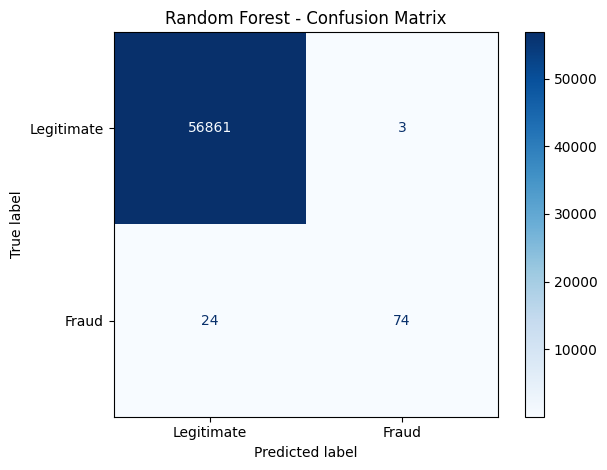

In [18]:
# Cell 13: Evaluate Random Forest using classification metrics,
# PR-AUC, ROC-AUC, and a confusion matrix.

from sklearn.metrics import (
    classification_report,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Classification Report:")
print(classification_report(
    y_test, rf_pred, digits=4, zero_division=0
))

print("PR-AUC:", round(
    average_precision_score(y_test, rf_prob), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, rf_prob), 4
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:
# Cell 16: Save the trained Logistic Regression and Random Forest models,
# along with the fitted StandardScaler, to Google Drive.

import joblib
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/DSP Project")
MODELS_DIR = PROJECT_DIR / "Models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save trained models and preprocessing object
joblib.dump(lr_model, MODELS_DIR / "logistic_regression.pkl")
joblib.dump(rf_model, MODELS_DIR / "random_forest.pkl")
joblib.dump(scaler, MODELS_DIR / "standard_scaler.pkl")

print("Models saved successfully!")
print("Saved files:")
for file in sorted(MODELS_DIR.glob("*.pkl")):
    print(file.name)

Models saved successfully!
Saved files:
logistic_regression.pkl
random_forest.pkl
standard_scaler.pkl


In [20]:
# Cell 17: Save the reported evaluation metrics for Logistic Regression
# and Random Forest in CSV and JSON formats.

import json
import pandas as pd

OUTPUT_DIR = PROJECT_DIR / "OutPut"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results = [
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.9755,
        "Fraud_Precision": 0.0610,
        "Fraud_Recall": 0.9184,
        "Fraud_F1_Score": 0.1144,
        "PR_AUC": 0.7190,
        "ROC_AUC": 0.9721
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.9995,
        "Fraud_Precision": 0.9610,
        "Fraud_Recall": 0.7551,
        "Fraud_F1_Score": 0.8457,
        "PR_AUC": 0.8589,
        "ROC_AUC": 0.9572
    }
]

results_df = pd.DataFrame(results)

# Save results
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

with open(OUTPUT_DIR / "model_comparison.json", "w") as file:
    json.dump(results, file, indent=4)

display(results_df)

print("Evaluation results saved successfully!")

,Model,Accuracy,Fraud_Precision,Fraud_Recall,Fraud_F1_Score,PR_AUC,ROC_AUC
0,Logistic Regression,0.9755,0.061,0.9184,0.1144,0.7190,0.9721
1,Random Forest,0.9995,0.961,0.7551,0.8457,0.8589,0.9572


Evaluation results saved successfully!


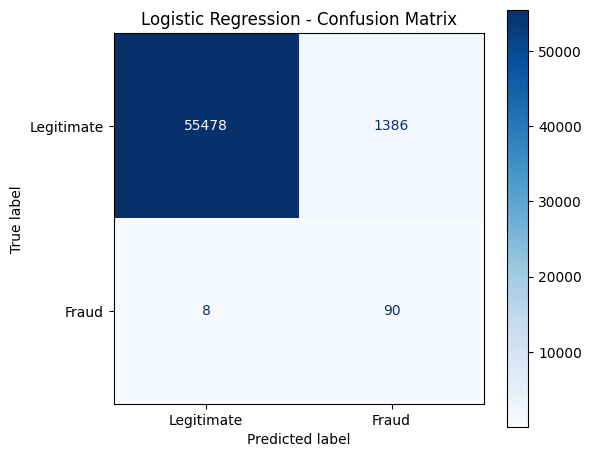

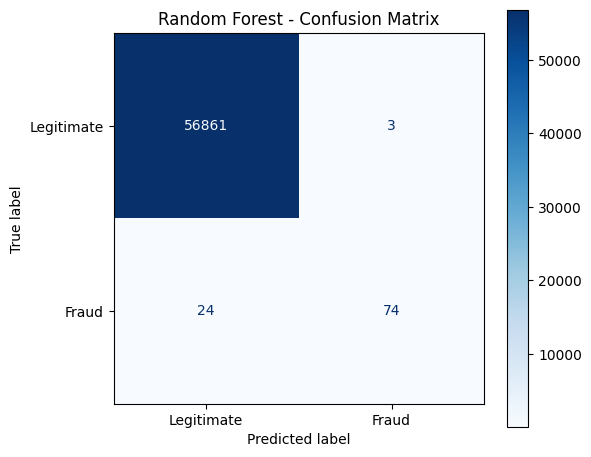

Confusion matrix plots saved successfully!


In [21]:
# Cell 18: Generate and save confusion matrix plots for both trained
# models using their predictions on the test set.

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Logistic Regression confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_model.predict(X_test_scaled),
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d",
    ax=ax
)
ax.set_title("Logistic Regression - Confusion Matrix")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Random Forest confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_model.predict(X_test),
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d",
    ax=ax
)
ax.set_title("Random Forest - Confusion Matrix")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Confusion matrix plots saved successfully!")